# TP3 · Predicción del tiempo de entrega
## Desarrollo de Sistemas de Inteligencia Artificial · Grupo 8

**Integrantes** 
- Ángel Soto: https://github.com/95851991-ifts24/DSIA_Soto_Angel 
- Brian Osorio: https://github.com/Lagastter/Desarrollo-Sistemas-IA-IFTS24
- Carla Pedrozo:https://github.com/CarlaPedrozo/DSIA_Pedrozo_Carla
- Marcela Cerda: https://github.com/17330973-MC/DSIA


## Introducción
Se continúa el proyecto con **Delivery Market Argentina**, integrando la exploración, limpieza y cuatro hipótesis de la segunda entrega con una nueva etapa de modelado predictivo. El notebook se ejecuta de principio a fin con el CSV original en la misma carpeta.

El análisis anterior mostró una relación positiva entre distancia y tiempo de entrega, sensible a las observaciones extremas. Esto motiva estudiar cuánto permiten anticipar los tiempos las características conocidas al confirmar un pedido.

## Objetivo del proyecto
**Comparar tres modelos de regresión para estimar el tiempo de entrega, en minutos, de pedidos que finalmente fueron entregados, usando características disponibles al confirmar el pedido.** La evaluación se limita a este subconjunto y al dataset sintético; no cubre cancelaciones, reembolsos ni asegura rendimiento en operaciones reales.

Se comparan regresión lineal regularizada (Ridge), árbol de decisión y bosque aleatorio. Se incluye una referencia adicional que siempre predice la mediana de entrenamiento. El criterio principal es el **error absoluto medio (MAE)**; RMSE y R² complementan la comparación. No se requiere aplicar los tres tipos de tarea de la consigna: los tres modelos resuelven el mismo objetivo de regresión.

## Organización y reproducibilidad
1. Descripción, EDA, limpieza y gráficos de las cuatro hipótesis, retomados del TP2.
2. Resumen de las conclusiones de las hipótesis.
3. Preparación para modelado, comparación mediante validación cruzada y evaluación final.
4. Selección del modelo, limitaciones y conclusión.

Se conserva el EDA sobre el conjunto completo porque ya fue realizado en el TP2. La reserva final se utiliza para evaluar el ajuste de los nuevos modelos, pero **no es un conjunto externo nunca explorado**. Los preprocesamientos aprendidos se ajustan dentro de cada partición de entrenamiento. La evaluación debe considerarse interna y exploratoria.

## Descripción del dataset

### Origen y características del dataset

El dataset *Delivery Market Argentina* fue generado con asistencia de Gemini, una herramienta de inteligencia artificial, mediante un proceso iterativo guiado por requerimientos definidos por un integrante del equipo. Su elaboración tuvo como finalidad disponer de información sintética sobre operaciones de delivery en Argentina para desarrollar las distintas etapas del proyecto académico.

Durante su construcción se solicitaron modificaciones específicas, incluyendo la incorporación de variables comerciales y operativas, variaciones intencionales en las denominaciones de ciudades y aplicaciones, ajustes en los montos de los pedidos y la presencia de valores faltantes y atípicos. Estas características fueron incorporadas para permitir la aplicación de técnicas de análisis exploratorio, limpieza y preparación de datos.

El archivo definitivo contiene 3.500 registros y 16 variables. Si bien se recuperó un script de referencia y evidencia del proceso de generación, no se dispone de una versión consolidada del código que permita reproducir exactamente el CSV final.

Debido a su naturaleza sintética, los resultados obtenidos deben interpretarse dentro del conjunto de datos generado y no como evidencia representativa del comportamiento real del mercado de delivery en Argentina.

## 🛳️ Importación de Librerías

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


## 1\. Carga y exploración de datos 🔎

### Carga del dataset y exploración inicial

Se realiza la carga del dataset seleccionado para verificar su estructura general, cantidad de registros, variables disponibles y tipos de datos\. Esta exploración inicial permite reconocer las características de la información antes de realizar transformaciones o análisis estadísticos\.

In [2]:
df_delivery_original = pd.read_csv("Dataset_Market_Delivery_Argentina.csv")
print("\n Se ha leído con éxito el archivo 'Dataset_Market_Delivery_Argentina.csv'")

# Copia del dataset para trabajar sin modificar el original
df_delivery = df_delivery_original.copy()



 Se ha leído con éxito el archivo 'Dataset_Market_Delivery_Argentina.csv'


### Información del Set

In [3]:
print('\nDimensiones del set:')
print(df_delivery.shape)



Dimensiones del set:
(3500, 16)


### Primeras 5 filas

In [4]:
print('\nPrimeras 5 filas:')
display(df_delivery.head())



Primeras 5 filas:


,id_pedido,app_delivery,ciudad,tipo_cliente,tipo_comida,dia_semana,franja_horaria,distancia_km,monto_pedido,aplica_promocion,descuento_aplicado,costo_envio,tiempo_entrega_minutos,metodo_pago,estado_pedido,calificacion_orden
0,PED_00001,PedidosYa,CABA,Standard,Hamburguesas,Viernes,Almuerzo,3.9,22400.0,Sí,4400.0,4500,NaN,Tarjeta_Debito,Entregado,NaN
1,PED_00002,Zonakids,Mendoza,Standard,Helado,Viernes,Almuerzo,0.9,42700.0,Sí,10900.0,3500,20.0,Efectivo,Cancelado,5.0
2,PED_00003,Rappi,Mar del Plata,PRO,Sushi,Domingo,Almuerzo,2.3,85000.0,Sí,21600.0,500,43.0,Tarjeta_Credito,Entregado,5.0
3,PED_00004,Rappi,CABA,PRO,Empanadas,Viernes,Cena,4.9,55500.0,Sí,12300.0,0,46.0,Tarjeta_Debito,Entregado,4.0
4,PED_00005,pedidos ya,La Plata,Standard,Hamburguesas,Viernes,Cena,1.2,27500.0,No,0.0,3500,25.0,MercadoPago,Entregado,5.0


### Información General

In [5]:
print('\nInformación General: ')
df_delivery.info()


Información General: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_pedido               3500 non-null   object 
 1   app_delivery            3500 non-null   object 
 2   ciudad                  3500 non-null   object 
 3   tipo_cliente            3500 non-null   object 
 4   tipo_comida             3500 non-null   object 
 5   dia_semana              3500 non-null   object 
 6   franja_horaria          3500 non-null   object 
 7   distancia_km            3500 non-null   float64
 8   monto_pedido            3500 non-null   float64
 9   aplica_promocion        3500 non-null   object 
 10  descuento_aplicado      3500 non-null   float64
 11  costo_envio             3500 non-null   int64  
 12  tiempo_entrega_minutos  3430 non-null   float64
 13  metodo_pago             3395 non-null   object 
 14  estado_pedido    

Interpretación de los Datos:

* La carga del dataset se realizó correctamente, obteniendo un conjunto de 3.500 registros y 16 variables que incluyen información comercial, geográfica y operativa de los pedidos de delivery.

* La exploración inicial permitió identificar variables categóricas y numéricas, así como la presencia de valores faltantes en cuatro columnas: `tiempo_entrega_minutos`, `metodo_pago`, `estado_pedido` y `calificacion_orden`.

* Estos resultados permiten reconocer la estructura general del dataset y establecer una base para evaluar la calidad de los datos antes de realizar los análisis estadísticos.

### Diagnóstico Estadístico y  Calidad de los Datos

Se realizará una evaluación inicial de la calidad del dataset mediante la identificación de valores faltantes, registros duplicados y valores únicos por variable\. Además, se calcularán estadísticas descriptivas de las variables numéricas para conocer sus principales características, rangos y medidas de tendencia central\.

In [6]:
resumen_calidad = pd.DataFrame({
    'Variable': df_delivery.columns,
    'Tipo de Datos': df_delivery.dtypes,
    'Valores Únicos': df_delivery.nunique(),
    'Valores Nulos': df_delivery.isnull().sum(),
    'Porcentaje de Nulos (%)': (df_delivery.isnull().sum() / len(df_delivery)) * 100
})

print(resumen_calidad)

                                      Variable Tipo de Datos  Valores Únicos  \
id_pedido                            id_pedido        object            3500   
app_delivery                      app_delivery        object              10   
ciudad                                  ciudad        object              14   
tipo_cliente                      tipo_cliente        object               2   
tipo_comida                        tipo_comida        object               7   
dia_semana                          dia_semana        object               7   
franja_horaria                  franja_horaria        object               4   
distancia_km                      distancia_km       float64             135   
monto_pedido                      monto_pedido       float64             667   
aplica_promocion              aplica_promocion        object               2   
descuento_aplicado          descuento_aplicado       float64             186   
costo_envio                        costo

### Comprobación de Registros Duplicados

In [7]:
print("\nRegistros Duplicados")
print("\nFilas Duplicadas:", df_delivery.duplicated().sum())
print("\nIDs Duplicados:", df_delivery['id_pedido'].duplicated().sum())



Registros Duplicados

Filas Duplicadas: 0

IDs Duplicados: 0


### Estadísticas Descriptivas

In [8]:
print("\nEstadísticas Descriptivas")
display(df_delivery.describe().T.round(2))


Estadísticas Descriptivas


,count,mean,std,min,25%,50%,75%,max
distancia_km,3500.0,2.97,4.21,0.3,1.5,2.2,3.4,59.3
monto_pedido,3500.0,37893.23,18217.03,15000.0,22700.0,35800.0,49300.0,115100.0
descuento_aplicado,3500.0,3080.83,4581.91,0.0,0.0,0.0,5600.0,33100.0
costo_envio,3500.0,2669.86,1822.56,0.0,500.0,3500.0,3500.0,6000.0
tiempo_entrega_minutos,3430.0,31.82,16.00,15.0,23.0,30.0,37.0,180.0
calificacion_orden,2625.0,4.15,1.12,1.0,4.0,5.0,5.0,5.0


Interpretación de los Datos:

El análisis descriptivo permitió identificar que el dataset no presenta registros completamente duplicados ni identificadores de pedido repetidos, lo que representa un aspecto favorable de su integridad\.

Las variables numéricas muestran diferencias entre sus medidas de tendencia central y valores máximos, particularmente en distancia y tiempo de entrega, donde se observan posibles valores atípicos que requieren una evaluación posterior\. Asimismo, se identifican valores faltantes en las variables de tiempo de entrega y calificación, que deberán considerarse durante el proceso de limpieza\.

Estos resultados evidencian la necesidad de profundizar en la calidad y distribución de los datos antes de establecer relaciones entre variables y evaluar las hipótesis del proyecto\.

## 2\. Limpieza de Datos

### 2\.1 Identificación de Inconsistencias en Variables Categóricas

Se analizarán los valores únicos y sus frecuencias en las variables categóricas para detectar posibles inconsistencias de escritura, diferencias de formato y categorías que requieran estandarización\. Esta evaluación permitirá determinar qué transformaciones son necesarias para garantizar la consistencia de los datos\.

In [9]:
columnas_categoricas = [
    'app_delivery',
    'ciudad',
    'tipo_cliente',
    'tipo_comida',
    'dia_semana',
    'franja_horaria',
    'aplica_promocion',
    'metodo_pago',
    'estado_pedido'
]

for columna in columnas_categoricas:
    print(f"\nVARIABLE: {columna}")
    print(df_delivery[columna].value_counts(dropna=False))



VARIABLE: app_delivery
app_delivery
PedidosYa     1173
Rappi         1060
UberEats       339
Zonakids       184
pedidos ya     137
PeYa           134
RAPPI          130
Pedidos Ya     120
rappi          112
rapi           111
Name: count, dtype: int64

VARIABLE: ciudad
ciudad
CABA                               1170
Mendoza                             353
Córdoba                             342
Mar del Plata                       259
La Plata                            255
C.A.B.A.                            224
caba                                208
Rosario                             201
Ciudad Autónoma de Buenos Aires     197
cordoba                              77
Cordoba                              61
ROSARIO                              61
rosario                              46
Cba                                  46
Name: count, dtype: int64

VARIABLE: tipo_cliente
tipo_cliente
Standard    2521
PRO          979
Name: count, dtype: int64

VARIABLE: tipo_comida
tipo_comida
Árab

El análisis de frecuencias permitió identificar inconsistencias en las variables `app_delivery` y `ciudad`, donde una misma categoría presenta diferentes formas de escritura, abreviaturas y variaciones en el uso de mayúsculas y acentos. Se identificaron 10 denominaciones de aplicaciones y 14 de ciudades, lo que podría distorsionar los resultados de los análisis posteriores.

Las variables `tipo_cliente`, `tipo_comida`, `dia_semana`, `franja_horaria` y `aplica_promocion` no presentan inconsistencias evidentes en sus categorías. Por su parte, `metodo_pago` y `estado_pedido` contienen valores faltantes que requieren una evaluación específica.

En consecuencia, se considera necesario estandarizar las categorías inconsistentes y analizar el tratamiento de los valores ausentes, conservando la integridad de la información original.

### 2\.2 Estandarización de app\_delivery

Mapeo

In [10]:
mapeo_apps = {
    'PedidosYa': 'PedidosYa',
    'pedidos ya': 'PedidosYa',
    'Pedidos Ya': 'PedidosYa',
    'PeYa': 'PedidosYa',
    'Rappi': 'Rappi',
    'RAPPI': 'Rappi',
    'rappi': 'Rappi',
    'rapi': 'Rappi'
}

Cantidad de categorías antes de limpiar

In [11]:
print("Categorías originales:",df_delivery_original['app_delivery'].nunique())


Categorías originales: 10


Aplicamos la estandarización

In [12]:
df_delivery['app_delivery'] = (
    df_delivery['app_delivery'].replace(mapeo_apps)
)

Verificamos los resultados

In [13]:
print("\nCategorías después de la limpieza:",df_delivery['app_delivery'].nunique())
print("\nFrecuencia por aplicación:")
display(df_delivery['app_delivery'].value_counts())


Categorías después de la limpieza: 4

Frecuencia por aplicación:


app_delivery
PedidosYa    1564
Rappi        1413
UberEats      339
Zonakids      184
Name: count, dtype: int64

Total de registros

In [14]:
print("\nTotal de registros:",df_delivery['app_delivery'].count())


Total de registros: 3500


Se realizó la estandarización de la variable `app_delivery`, unificando diferencias de escritura, mayúsculas y abreviaturas correspondientes a una misma aplicación. Como resultado, las 10 denominaciones originales se consolidaron en cuatro categorías: PedidosYa (1.564 registros), Rappi (1.413), UberEats (339) y Zonakids (184).

La transformación permitió mejorar la consistencia de la variable sin alterar la cantidad total de registros, facilitando comparaciones más precisas entre las plataformas durante el análisis posterior.

### 2\.3 Estandarización de ciudad

In [15]:
print("Categorías originales de Ciudades:",df_delivery_original['ciudad'].nunique())

Categorías originales de Ciudades: 14


### Diccionario de equivalencias para ciudades

In [16]:
mapeo_ciudades = {
    'Ciudad Autónoma de Buenos Aires': 'CABA',
    'C.A.B.A.': 'CABA',
    'caba': 'CABA',
    'cordoba': 'Córdoba',
    'Cordoba': 'Córdoba',
    'Cba': 'Córdoba',
    'rosario': 'Rosario',
    'ROSARIO': 'Rosario'
}

### Reemplazo de Ciudades

In [17]:
df_delivery['ciudad'] = df_delivery['ciudad'].replace(mapeo_ciudades)
print("\nCategorías de Ciudades después de la limpieza:",df_delivery['ciudad'].nunique())


Categorías de Ciudades después de la limpieza: 6


### Frecuencia por ciudad

In [18]:
print("\nFrecuencia por ciudad:")
display(df_delivery['ciudad'].value_counts())


Frecuencia por ciudad:


ciudad
CABA             1799
Córdoba           526
Mendoza           353
Rosario           308
Mar del Plata     259
La Plata          255
Name: count, dtype: int64

### Total de registros

In [19]:
print("\nTotal de registros:",df_delivery['ciudad'].count())


Total de registros: 3500


La estandarización de la variable `ciudad` permitió reducir las 14 denominaciones originales a seis categorías, unificando diferencias de escritura, uso de mayúsculas, tildes y abreviaturas. Se consideró `Cba` como una abreviatura de Córdoba, de acuerdo con el contexto geográfico del dataset.

El procedimiento conservó los 3.500 registros originales y permitió obtener frecuencias consistentes por ciudad, evitando que una misma ubicación aparezca representada en categorías diferentes.

### 2\.4 Evaluación de Valores Faltantes

### Variables que presentan valores faltantes

In [20]:
columnas_incompletas = [
    'metodo_pago',
    'estado_pedido',
    'tiempo_entrega_minutos',
    'calificacion_orden'
]


### Resumen de valores faltantes

In [21]:
resumen_nulos = pd.DataFrame({
    'Valores nulos': df_delivery[columnas_incompletas].isna().sum(),
    'Porcentaje (%)': (
        df_delivery[columnas_incompletas].isna().mean() * 100
    ).round(2)
})

print("Resumen de valores faltantes:")
display(resumen_nulos)

Resumen de valores faltantes:


,Valores nulos,Porcentaje (%)
metodo_pago,105,3.0
estado_pedido,35,1.0
tiempo_entrega_minutos,70,2.0
calificacion_orden,875,25.0


### 2\.4 Evaluación de Valores Faltantes con el estado del pedido

### Relación de los datos faltantes con el estado del pedido

In [22]:
for variable in ['tiempo_entrega_minutos', 'calificacion_orden']:
    print(f"\nDisponibilidad de {variable} según estado del pedido:")

    tabla = pd.crosstab(
        df_delivery['estado_pedido'].fillna('Sin estado'),
        df_delivery[variable].isna()
    )

    display(tabla.rename(columns={
        False: 'Con dato',
        True: 'Sin dato'
    }))



Disponibilidad de tiempo_entrega_minutos según estado del pedido:


tiempo_entrega_minutos,Con dato,Sin dato
estado_pedido,,
Cancelado,308,6
Entregado,2989,59
Reembolsado,100,3
Sin estado,33,2



Disponibilidad de calificacion_orden según estado del pedido:


calificacion_orden,Con dato,Sin dato
estado_pedido,,
Cancelado,229,85
Entregado,2290,758
Reembolsado,81,22
Sin estado,25,10


**Interpretación de la Evaluación de valores Faltantes**
El análisis identificó valores faltantes en cuatro variables: método de pago (3 %), estado del pedido (1 %), tiempo de entrega (2 %) y calificación de la orden (25 %).

Al relacionar la disponibilidad de los datos con el estado del pedido, se observó que las calificaciones y los tiempos de entrega se encuentran registrados tanto en pedidos entregados como cancelados y reembolsados. Asimismo, existen pedidos entregados sin calificación.

Por lo tanto, no resulta adecuado atribuir automáticamente los valores faltantes a un estado específico ni reemplazarlos por cero. Se propone identificar explícitamente la ausencia de información en las variables categóricas y conservar temporalmente los valores nulos de las variables numéricas hasta definir su tratamiento según los objetivos del análisis y modelado.

### 2\.5 Tratamiento de Valores Faltantes Categóricos

### Identificar explícitamente los valores faltantes categóricos

In [23]:
df_delivery['metodo_pago'] = df_delivery['metodo_pago'].fillna('No informado')
df_delivery['estado_pedido'] = df_delivery['estado_pedido'].fillna('No informado')

### Comprobar el resultado del tratamiento

In [24]:
print("Valores faltantes después del tratamiento categórico:")
display(df_delivery[columnas_incompletas].isna().sum())

Valores faltantes después del tratamiento categórico:


metodo_pago                 0
estado_pedido               0
tiempo_entrega_minutos     70
calificacion_orden        875
dtype: int64

### Distribución actualizada

In [25]:
print("\nDistribución actualizada de estados:")
display(df_delivery['estado_pedido'].value_counts())

print("\nTotal de registros:",len(df_delivery))


Distribución actualizada de estados:


estado_pedido
Entregado       3048
Cancelado        314
Reembolsado      103
No informado      35
Name: count, dtype: int64


Total de registros: 3500


**Interpretación del Resultado**
Se reemplazaron los valores faltantes de `metodo_pago` y `estado_pedido` por la categoría «No informado», permitiendo identificar explícitamente la ausencia de información sin asignar valores desconocidos a categorías existentes.

Después del tratamiento, ambas variables categóricas quedaron sin valores nulos y se conservaron los 3.500 registros del dataset. Los valores faltantes de `tiempo_entrega_minutos` y `calificacion_orden` se mantuvieron sin modificaciones, ya que su imputación requiere considerar el significado de cada variable y los objetivos del análisis posterior.

### 2\.6 Validación de Rangos Numéricos

In [26]:
# Verificación de posibles inconsistencias numéricas
validaciones_numericas = {
    'Distancias menores o iguales a cero':
        (df_delivery['distancia_km'] <= 0).sum(),

    'Montos menores o iguales a cero':
        (df_delivery['monto_pedido'] <= 0).sum(),

    'Descuentos negativos':
        (df_delivery['descuento_aplicado'] < 0).sum(),

    'Descuentos mayores que el monto':
        (df_delivery['descuento_aplicado'] > df_delivery['monto_pedido']).sum(),

    'Costos de envío negativos':
        (df_delivery['costo_envio'] < 0).sum(),

    'Tiempos de entrega menores o iguales a cero':
        (df_delivery['tiempo_entrega_minutos'] <= 0).sum(),

    'Calificaciones fuera del rango 1 a 5':
        (
            df_delivery['calificacion_orden'].notna()
            & ~df_delivery['calificacion_orden'].between(1, 5)
        ).sum()
}

# Mostrar las verificaciones
display(
    pd.Series(
        validaciones_numericas,
        name='Registros detectados'
    ).to_frame()
)

,Registros detectados
Distancias menores o iguales a cero,0
Montos menores o iguales a cero,0
Descuentos negativos,0
Descuentos mayores que el monto,0
Costos de envío negativos,0
Tiempos de entrega menores o iguales a cero,0
Calificaciones fuera del rango 1 a 5,0


**Interpretación**
La validación de rangos numéricos no identificó registros que incumplan las condiciones establecidas para las variables evaluadas. Las distancias, montos y tiempos registrados presentan valores positivos; los descuentos no superan el monto de los pedidos y las calificaciones disponibles se encuentran dentro del intervalo de 1 a 5.

Estos resultados indican que no se requieren correcciones por valores numéricos fuera de los rangos definidos. No obstante, se mantienen los valores faltantes y las observaciones atípicas identificadas previamente, cuyo tratamiento debe evaluarse por separado.

### 2\.7 Revisión de Valores Atípicos

### Evaluación de valores atípicos mediante IQR

In [27]:
variables_evaluadas = [
    'distancia_km',
    'tiempo_entrega_minutos',
    'monto_pedido'
]

resultados_atipicos = []

for variable in variables_evaluadas:
    q1 = df_delivery[variable].quantile(0.25)
    q3 = df_delivery[variable].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    cantidad = (
        (df_delivery[variable] < limite_inferior) |
        (df_delivery[variable] > limite_superior)
    ).sum()

    resultados_atipicos.append({
        'Variable': variable,
        'Límite superior': round(limite_superior, 2),
        'Valores atípicos': cantidad
    })

display(pd.DataFrame(resultados_atipicos))

,Variable,Límite superior,Valores atípicos
0,distancia_km,6.25,179
1,tiempo_entrega_minutos,58.00,73
2,monto_pedido,89200.00,28


**Interpretación de la Revisión**
La evaluación mediante el rango intercuartílico (IQR) identificó 179 valores atípicos en `distancia_km`, 73 en `tiempo_entrega_minutos` y 28 en `monto_pedido`. Estos resultados muestran la presencia de observaciones alejadas de los rangos habituales de cada variable, sin que ello implique necesariamente errores de registro.

Se decidió conservar los valores atípicos y los registros originales, ya que no se cuenta con evidencia suficiente para justificar su eliminación o modificación. Su posible influencia sobre los resultados estadísticos y el desempeño de futuros modelos predictivos deberá evaluarse en etapas posteriores.

## 3\. Visualizaciones y Análisis

## Análisis Univariado

### Gráfico 1: Distribución de los montos de pedido

Se analizará la distribución de los montos de pedido mediante un histograma, identificando la concentración de valores, su dispersión y las posibles diferencias entre la media y la mediana\. Este análisis permitirá comprender el comportamiento de una de las principales variables económicas del dataset\.

 Análisis univariado: distribución de montos de pedido

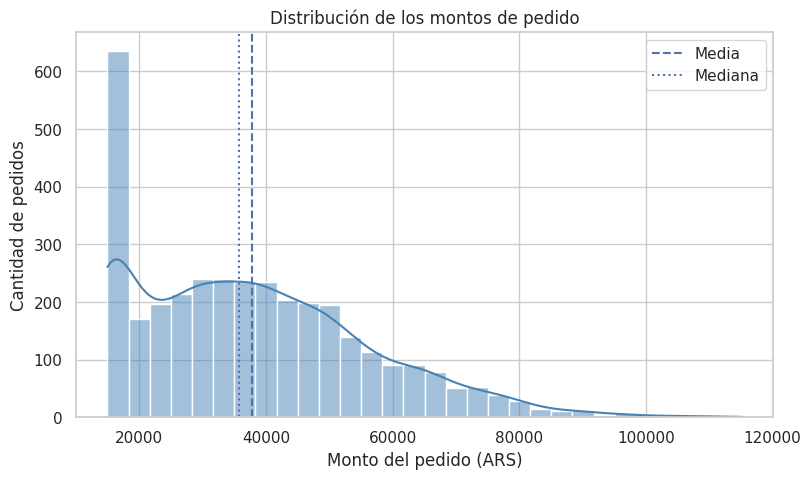

Media: $37,893.23
Mediana: $35,800.00


In [28]:
media_monto = df_delivery['monto_pedido'].mean()
mediana_monto = df_delivery['monto_pedido'].median()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_delivery,
    x='monto_pedido',
    bins=30,
    kde=True,
    color ='steelblue'
)

plt.axvline(media_monto, linestyle='--', label='Media')
plt.axvline(mediana_monto, linestyle=':', label='Mediana')

plt.title('Distribución de los montos de pedido')
plt.xlabel('Monto del pedido (ARS)')
plt.ylabel('Cantidad de pedidos')
plt.legend()
plt.show()

print(f"Media: ${media_monto:,.2f}")
print(f"Mediana: ${mediana_monto:,.2f}")


📌 Interpretación del gráfico

El histograma de `monto_pedido` presenta una distribución asimétrica hacia la derecha, con una concentración destacada de pedidos en los montos más bajos y una disminución progresiva de las frecuencias hacia los valores elevados.

La media (\$37.893,23) supera a la mediana (\$35.800), lo que resulta coherente con la influencia de pedidos de mayor importe. Esta distribución evidencia diferencias en los montos registrados y respalda la necesidad de considerar las observaciones atípicas al realizar análisis estadísticos posteriores.

### Gráfico 2: Frecuencia por Tipo de Comida

Se analizará la distribución de pedidos según el tipo de comida mediante un gráfico de barras, con el objetivo de identificar las categorías más frecuentes y comparar su participación dentro del dataset\.

Análisis univariado: pedidos por tipo de comida

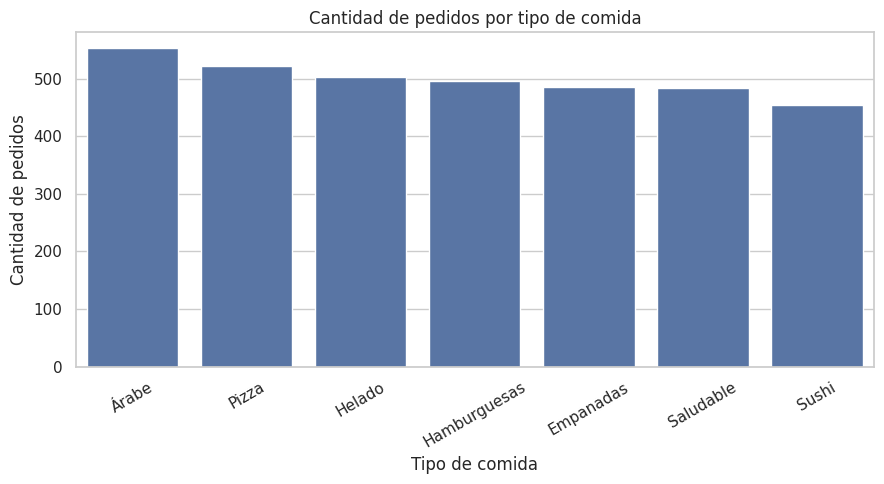

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_delivery,
    x='tipo_comida',
    order=df_delivery['tipo_comida'].value_counts().index
)

plt.title('Cantidad de pedidos por tipo de comida')
plt.xlabel('Tipo de comida')
plt.ylabel('Cantidad de pedidos')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Distribución porcentual

In [30]:
porcentaje_comidas = (
    df_delivery['tipo_comida']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Porcentaje de pedidos por tipo de comida:")
display(porcentaje_comidas)

Porcentaje de pedidos por tipo de comida:


tipo_comida
Árabe           15.80
Pizza           14.94
Helado          14.37
Hamburguesas    14.17
Empanadas       13.89
Saludable       13.83
Sushi           13.00
Name: proportion, dtype: float64

**Interpretación del Análisis por Tipo de Comida**
La distribución de pedidos según el tipo de comida muestra frecuencias relativamente equilibradas entre las siete categorías. La comida árabe presenta la mayor participación (15,80 %), seguida de pizza (14,94 %) y helado (14,37 %), mientras que sushi registra la menor proporción (13 %).

La diferencia entre las categorías de mayor y menor frecuencia es de 2,80 puntos porcentuales, por lo que no se observa un predominio marcado de un tipo de comida. Estos resultados describen la distribución del dataset sintético y no representan necesariamente las preferencias reales de los consumidores argentinos.

## Análisis Bivariado

### Gráfico 1: Monto de pedido según tipo de cliente

Se analizará la distribución de los montos de pedido según el tipo de cliente \(PRO y Standard\) mediante un diagrama de cajas\. Se compararán las medianas, la dispersión y los posibles valores atípicos de ambos grupos, complementando la visualización con estadísticas descriptivas para identificar posibles diferencias en sus comportamientos de compra\.

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


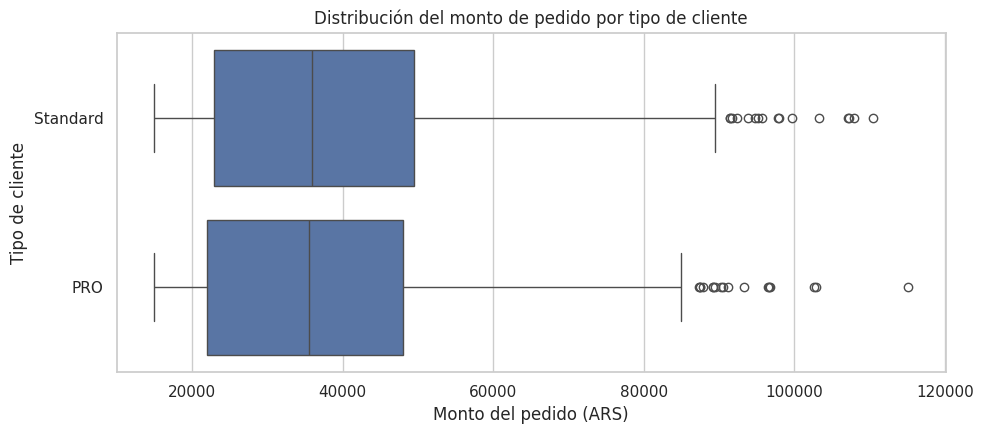

In [31]:
# Análisis bivariado: monto de pedido según tipo de cliente
plt.figure(figsize=(10, 4.5))

sns.boxplot(
    data=df_delivery,
    x='monto_pedido',
    y='tipo_cliente',
    order=['Standard', 'PRO']
)

plt.title('Distribución del monto de pedido por tipo de cliente')
plt.xlabel('Monto del pedido (ARS)')
plt.ylabel('Tipo de cliente')
plt.tight_layout()
plt.show()

📌 Interpretación del gráfico

El diagrama de cajas muestra distribuciones similares en los montos de pedido de los clientes Standard y PRO\. Los clientes Standard presentan un promedio de $38\.049,66 y una mediana de $36\.000, mientras que los clientes PRO registran un promedio de $37\.490,40 y una mediana de $35\.500\.

Estadísticas descriptivas por tipo de cliente

In [32]:
resumen_clientes = df_delivery.groupby('tipo_cliente')['monto_pedido'].agg(
    cantidad='count',
    promedio='mean',
    mediana='median',
    desviacion='std'
).round(2)

print("Comparación de montos por tipo de cliente:")
display(resumen_clientes)

Comparación de montos por tipo de cliente:


,cantidad,promedio,mediana,desviacion
tipo_cliente,,,,
PRO,979,37490.40,35500.0,18275.66
Standard,2521,38049.66,36000.0,18195.44


Las diferencias entre ambos grupos son reducidas y presentan niveles de dispersión semejantes, con valores atípicos en las dos categorías. Por lo tanto, el análisis descriptivo no evidencia diferencias marcadas en los montos de pedido según el tipo de cliente, aunque se requerirían pruebas estadísticas adicionales para evaluar su significación.

### Gráfico 2: Distancia y tiempo de entrega

Se analizará la relación entre la distancia recorrida y el tiempo de entrega de los pedidos mediante un gráfico de dispersión. Se considerarán únicamente los pedidos registrados como entregados que cuenten con información de tiempo disponible. Además, se calculará el coeficiente de correlación de Pearson para evaluar la dirección e intensidad de la asociación lineal entre ambas variables.

Análisis bivariado: distancia y tiempo de entrega

Seleccionar pedidos entregados con tiempo disponible

In [33]:
df_entregados = df_delivery.loc[
    (df_delivery['estado_pedido'] == 'Entregado') &
    (df_delivery['tiempo_entrega_minutos'].notna())
].copy()
print(f"Pedidos analizados: {len(df_entregados)}")

Pedidos analizados: 2989


Calcular la correlación de Pearson

In [34]:
correlacion = df_entregados[
    ['distancia_km', 'tiempo_entrega_minutos']
].corr().iloc[0, 1]
print(f"Correlación de Pearson: {correlacion:.4f}")

Correlación de Pearson: 0.8805


Visualizar la relación entre ambas variables

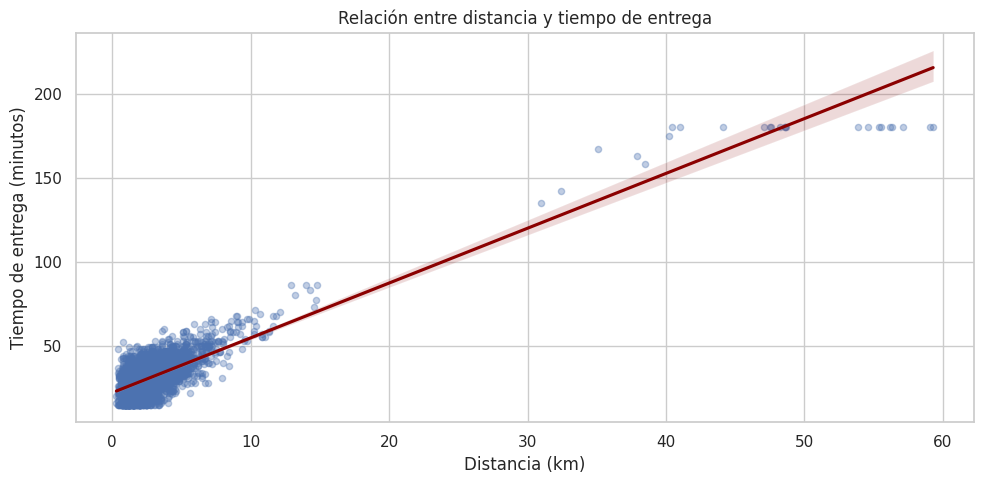

In [35]:
plt.figure(figsize=(10, 5))

sns.regplot(
    data=df_entregados,
    x='distancia_km',
    y='tiempo_entrega_minutos',
    scatter_kws={'alpha': 0.35, 's': 20},
    line_kws={'color': 'darkred'}
)

plt.title('Relación entre distancia y tiempo de entrega')
plt.xlabel('Distancia (km)')
plt.ylabel('Tiempo de entrega (minutos)')
plt.tight_layout()
plt.show()

📌 **Interpretación del gráfico**

Visualizando el grafico que relaciona la distancia y el tiempo de entrega, se decide analizar los valores extremos

Análisis de sensibilidad a valores extremos
Seleccionar pedidos dentro de los límites IQR previos

In [36]:

df_entregados_habituales = df_entregados.loc[
    (df_entregados['distancia_km'] <= 6.25) &
    (df_entregados['tiempo_entrega_minutos'] <= 58)
].copy()

# Calcular correlación en ambos conjuntos
corr_completa = df_entregados[
    ['distancia_km', 'tiempo_entrega_minutos']
].corr().iloc[0, 1]

corr_habitual = df_entregados_habituales[
    ['distancia_km', 'tiempo_entrega_minutos']
].corr().iloc[0, 1]

# Comparar resultados
comparacion_correlaciones = pd.DataFrame({
    'Conjunto': ['Todos los entregados', 'Dentro de límites IQR'],
    'Pedidos': [len(df_entregados), len(df_entregados_habituales)],
    'Correlación de Pearson': [
        round(corr_completa, 4),
        round(corr_habitual, 4)
    ]
})

display(comparacion_correlaciones)

,Conjunto,Pedidos,Correlación de Pearson
0,Todos los entregados,2989,0.8805
1,Dentro de límites IQR,2825,0.5264


El análisis de los 2.989 pedidos entregados con tiempos disponibles mostró una correlación lineal positiva fuerte entre la distancia y el tiempo de entrega (r = 0,8805).

Al realizar un análisis de sensibilidad restringido a los límites IQR, la correlación disminuyó a 0,5264 en 2.825 pedidos, manteniendo una asociación positiva de intensidad moderada. Esta diferencia evidencia que las observaciones extremas y el rango de valores considerados influyen en la intensidad de la relación estimada.

Se decidió conservar los registros originales y considerar esta variación al interpretar los resultados. Debido a la naturaleza sintética del dataset, las asociaciones observadas no deben generalizarse al comportamiento real de los servicios de delivery.

### Gráfico 3 - Promociones por aplicación

Se analizará la distribución porcentual de los pedidos con y sin promoción según la aplicación de delivery. Se utilizará un gráfico de barras apiladas para comparar las proporciones dentro de cada plataforma, evitando que las diferencias en la cantidad total de pedidos condicionen la comparación.

Análisis bivariado: promociones por aplicación

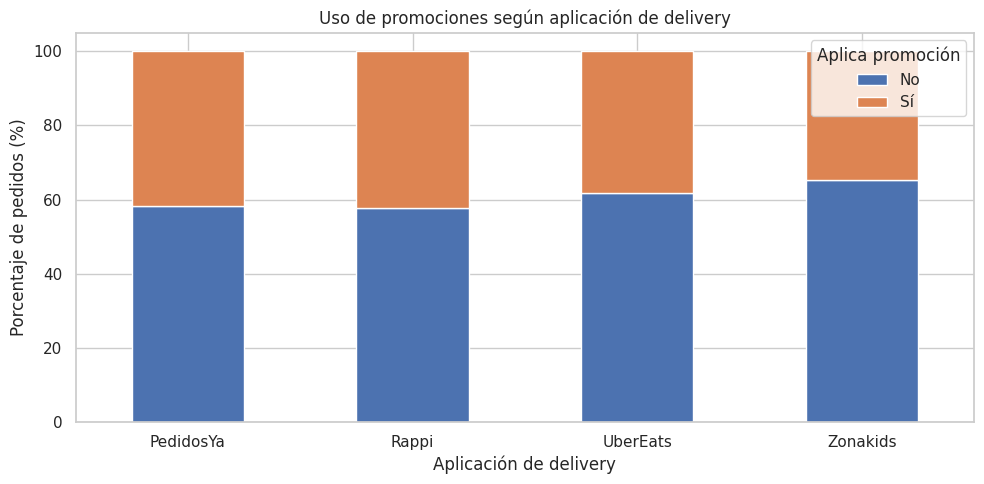

In [37]:
tabla_promociones = pd.crosstab(
    df_delivery['app_delivery'],
    df_delivery['aplica_promocion'],
    normalize='index'
).mul(100).round(2)

# Ordenar las categorías de promociones
tabla_promociones = tabla_promociones[['No', 'Sí']]

# Visualización porcentual
tabla_promociones.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Uso de promociones según aplicación de delivery')
plt.xlabel('Aplicación de delivery')
plt.ylabel('Porcentaje de pedidos (%)')
plt.xticks(rotation=0)
plt.legend(title='Aplica promoción')
plt.tight_layout()
plt.show()



📌 Interpretación del gráfico

El análisis bivariado muestra diferencias en la proporción de pedidos con promoción entre las aplicaciones de delivery\. Rappi registra el porcentaje más elevado \(42,39 %\), seguida de PedidosYa \(41,82 %\), UberEats \(38,35 %\) y Zonakids \(34,78 %\)\.

Distribución porcentual de Promociones

In [38]:
print("Distribución porcentual de promociones:")
display(tabla_promociones)

Distribución porcentual de promociones:


aplica_promocion,No,Sí
app_delivery,,
PedidosYa,58.18,41.82
Rappi,57.61,42.39
UberEats,61.65,38.35
Zonakids,65.22,34.78


Aunque las cuatro plataformas presentan pedidos con y sin promoción, se observan variaciones en la distribución porcentual. Estas diferencias describen el comportamiento del dataset sintético y no permiten establecer conclusiones sobre las estrategias promocionales reales de las empresas ni sobre su significación estadística.

Aunque las cuatro plataformas presentan pedidos con y sin promoción, se observan variaciones en la distribución porcentual\. Estas diferencias describen el comportamiento del dataset sintético y no permiten establecer conclusiones sobre las estrategias promocionales reales de las empresas ni sobre su significación estadística\.

## Analisis Multivariado

### Gráfico 1: Monto promedio de pedido según franja horaria y tipo de cliente

Se analizará el monto promedio de los pedidos según la franja horaria, diferenciando entre clientes Standard y PRO. Esta comparación permitirá explorar si existen variaciones en los importes de los pedidos al considerar conjuntamente ambas características.

/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


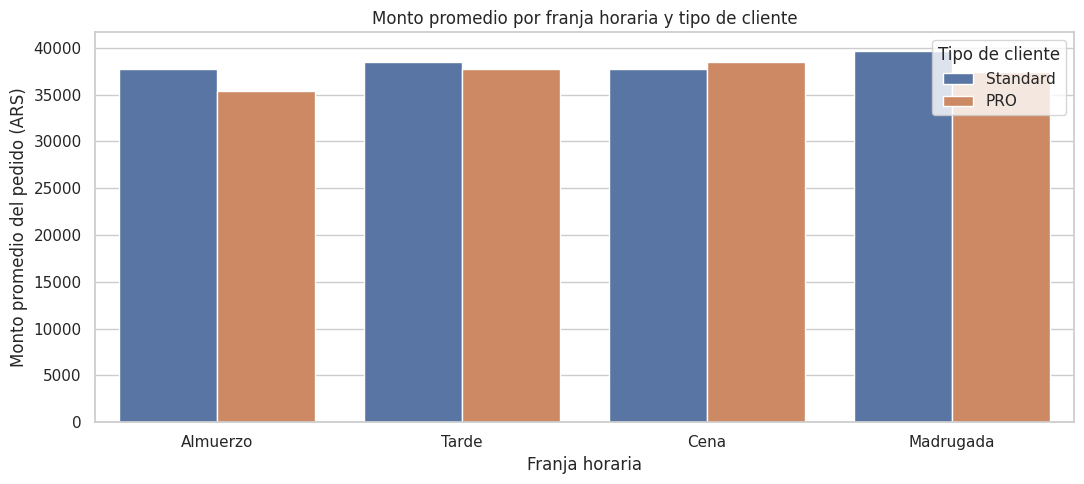

In [39]:
# Análisis multivariado: monto, franja horaria y tipo de cliente
orden_franjas = ['Almuerzo', 'Tarde', 'Cena', 'Madrugada']

plt.figure(figsize=(11, 5))

sns.barplot(
    data=df_delivery,
    x='franja_horaria',
    y='monto_pedido',
    hue='tipo_cliente',
    order=orden_franjas,
    estimator='mean',
    errorbar=None
)

plt.title('Monto promedio por franja horaria y tipo de cliente')
plt.xlabel('Franja horaria')
plt.ylabel('Monto promedio del pedido (ARS)')
plt.legend(title='Tipo de cliente')
plt.tight_layout()
plt.show()



📌 Interpretación del gráfico

El análisis multivariado muestra variaciones en los montos promedio de pedido según la franja horaria y el tipo de cliente. Los clientes Standard presentan promedios superiores durante el almuerzo, la tarde y la madrugada, mientras que los clientes PRO registran un promedio ligeramente mayor durante la cena.

Las diferencias observadas no muestran un patrón uniforme entre ambos tipos de cliente. Aunque los tamaños de los grupos son diferentes, todas las combinaciones cuentan con observaciones suficientes para realizar una comparación descriptiva. Estos resultados no permiten establecer diferencias estadísticamente significativas sin aplicar pruebas adicionales.

Promedios y cantidad de pedidos por grupo

In [40]:

resumen_franjas = df_delivery.groupby(
    ['franja_horaria', 'tipo_cliente']
)['monto_pedido'].agg(
    cantidad='count',
    promedio='mean'
).round(2)

display(resumen_franjas)

cantidad  promedio
franja_horaria tipo_cliente                    
Almuerzo       PRO                239  35410.46
               Standard           621  37780.52
Cena           PRO                474  38468.99
               Standard          1304  37772.78
Madrugada      PRO                108  37393.52
               Standard           231  39661.47
Tarde          PRO                158  37767.09
               Standard           365  38476.71

## 4\. Planteo de Hipótesis

###  Hipótesis 1: Relación entre promociones y monto de pedido

Se plantea que los pedidos con promoción presentan diferencias en su monto promedio respecto de aquellos sin promoción. Para explorar esta hipótesis, se compararán los montos de ambos grupos mediante un gráfico de barras y estadísticas descriptivas, considerando el número de pedidos correspondiente a cada categoría.

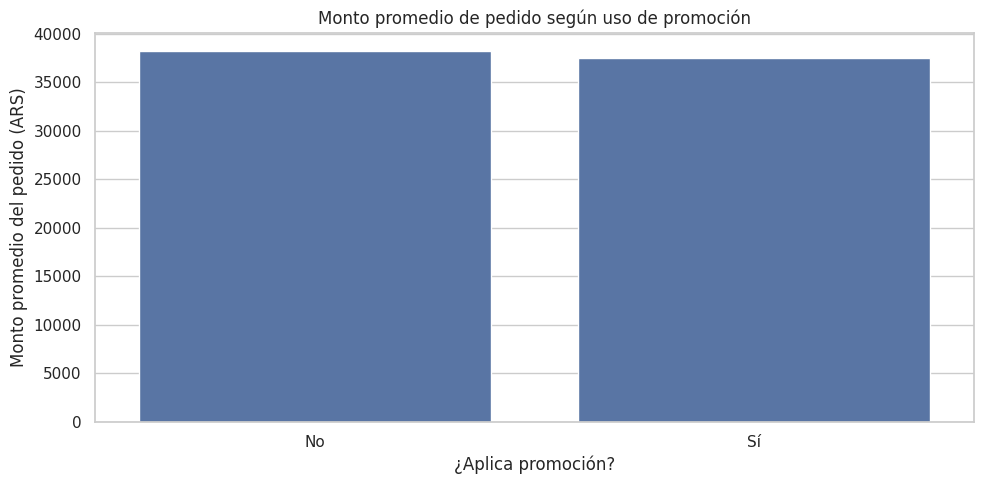

In [41]:
# Hipótesis 1: monto promedio según aplicación de promoción
resumen_promociones = df_delivery.groupby(
    'aplica_promocion'
)['monto_pedido'].agg(
    cantidad='count',
    promedio='mean',
    mediana='median'
).round(2)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_delivery,
    x='aplica_promocion',
    y='monto_pedido',
    order=['No', 'Sí'],
    estimator='mean',
    errorbar=None
)

plt.title('Monto promedio de pedido según uso de promoción')
plt.xlabel('¿Aplica promoción?')
plt.ylabel('Monto promedio del pedido (ARS)')
plt.tight_layout()
plt.show()



**Explicación del Desarrollo**
Para evaluar la hipótesis, se agruparon los pedidos según la variable `aplica_promocion`, diferenciando aquellos con y sin promoción. Se calcularon la cantidad de registros, la media y la mediana de `monto_pedido` para cada grupo.

Posteriormente, se elaboró un gráfico de barras que permitió comparar los montos promedio. Los pedidos sin promoción registraron una media de \$38.181,83, mientras que aquellos con promoción alcanzaron \$37.483,76, con una diferencia de \$698,07 (1,83 %).

Comparacion de montos segun promoción

In [42]:
print("Comparación de montos según promoción:")
display(resumen_promociones)

Comparación de montos según promoción:


,cantidad,promedio,mediana
aplica_promocion,,,
No,2053,38181.83,35900.0
Sí,1447,37483.76,35500.0


**Conclusión de la Hipótesis**
Se observa el patrón planteado a nivel descriptivo, ya que se identificó una diferencia en los montos promedio de ambos grupos. Sin embargo, la diferencia observada es reducida (1,83 %), por lo que no evidencia una variación importante en el comportamiento de los montos.

En consecuencia, los resultados respaldan descriptivamente la existencia de una diferencia, pero no permiten determinar si es estadísticamente significativa sin aplicar una prueba adicional.

### Hipótesis 2 : Asociación entre la aplicación de delivery y el uso de promociones

Se plantea que la proporción de pedidos con promoción varía según la aplicación de delivery utilizada.

Para evaluar esta hipótesis, se analizarán las variables categóricas `app_delivery` y `aplica_promocion`. Se tomará como referencia el gráfico de barras apiladas del análisis bivariado y se aplicará una prueba de chi-cuadrado de independencia para examinar si existe evidencia estadística de asociación entre ambas variables.

**Visualización de referencia:** Gráfico 3 del Análisis Bivariado — *Uso de promociones según aplicación de delivery*. Esta visualización permite comparar las proporciones de pedidos con y sin promoción por plataforma y complementa la prueba de chi-cuadrado presentada en esta hipótesis.

In [43]:
# Hipótesis 2: asociación entre aplicación y promociones

from scipy.stats import chi2_contingency

# Frecuencias absolutas observadas
tabla_contingencia = pd.crosstab(
    df_delivery['app_delivery'],
    df_delivery['aplica_promocion']
)

print("Tabla de contingencia:")
display(tabla_contingencia)



Tabla de contingencia:


aplica_promocion,No,Sí
app_delivery,,
PedidosYa,910,654
Rappi,814,599
UberEats,209,130
Zonakids,120,64


Prueba de chi\-cuadrado de independencia

In [44]:

chi2, p_valor, grados_libertad, esperados = chi2_contingency(
    tabla_contingencia
)

print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_valor:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Frecuencia esperada mínima: {esperados.min():.2f}")

Chi-cuadrado: 5.3049
Valor p: 0.1508
Grados de libertad: 3
Frecuencia esperada mínima: 76.07


**Explicación del Desarrollo**
Para evaluar la hipótesis, se analizaron las variables categóricas `app_delivery` y `aplica_promocion`. Inicialmente, se compararon los porcentajes de pedidos con promoción por aplicación mediante un gráfico de barras apiladas, observándose valores entre el 34,78 % de Zonakids y el 42,39 % de Rappi.

Posteriormente, se construyó una tabla de contingencia con las frecuencias absolutas y se aplicó una prueba de chi-cuadrado de independencia, obteniendo un estadístico χ² = 5,3049, con 3 grados de libertad y un valor p = 0,1508.

**Conclusión de la Hipótesis**
La hipótesis no obtuvo respaldo estadístico suficiente. Aunque se identificaron diferencias descriptivas en las proporciones de pedidos con promoción entre las aplicaciones, el valor p obtenido (0,1508) es superior al nivel de significación establecido (0,05).

Por lo tanto, no se rechaza la hipótesis nula de independencia entre ambas variables. Esto no demuestra que sean independientes, sino que los datos analizados no aportan evidencia estadística suficiente para afirmar una asociación. Además, los resultados corresponden a un dataset sintético y no pueden generalizarse al mercado real.

### Hipótesis 3: Asociación entre distancia y tiempo de entrega

Se plantea que existe una asociación lineal positiva entre la distancia recorrida y el tiempo de entrega de los pedidos. Para evaluarla, se utilizarán el gráfico de dispersión y los coeficientes de correlación de Pearson obtenidos en el análisis bivariado, considerando también la influencia de los valores extremos.

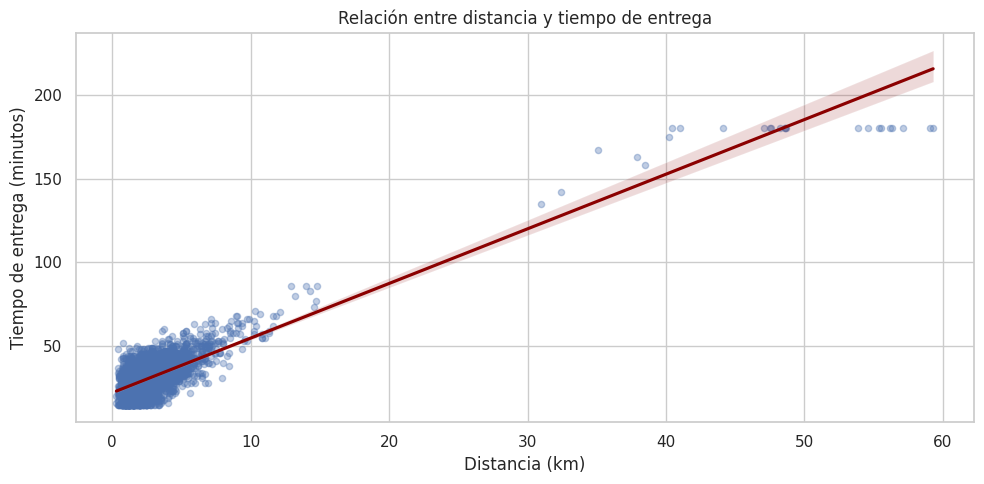

Pedidos analizados: 2989
Correlación de Pearson: 0.8805


In [45]:
df_entregados = df_delivery.loc[
    (df_delivery['estado_pedido'] == 'Entregado') &
    (df_delivery['tiempo_entrega_minutos'].notna())
].copy()

# Calcular la correlación de Pearson
correlacion = df_entregados[
    ['distancia_km', 'tiempo_entrega_minutos']
].corr().iloc[0, 1]

# Visualizar la relación entre ambas variables
plt.figure(figsize=(10, 5))

sns.regplot(
    data=df_entregados,
    x='distancia_km',
    y='tiempo_entrega_minutos',
    scatter_kws={'alpha': 0.35, 's': 20},
    line_kws={'color': 'darkred'}
)

plt.title('Relación entre distancia y tiempo de entrega')
plt.xlabel('Distancia (km)')
plt.ylabel('Tiempo de entrega (minutos)')
plt.tight_layout()
plt.show()

print(f"Pedidos analizados: {len(df_entregados)}")
print(f"Correlación de Pearson: {correlacion:.4f}")

**Explicación del Desarrollo de la Hipótesis**
Se seleccionaron los pedidos registrados como entregados que contaban con información sobre el tiempo de entrega, obteniendo 2.989 observaciones. Se elaboró un gráfico de dispersión entre `distancia_km` y `tiempo_entrega_minutos`, incorporando una línea de regresión para visualizar la tendencia general.

Se calculó el coeficiente de correlación de Pearson, obteniendo un valor de 0,8805. Posteriormente, se realizó un análisis de sensibilidad considerando únicamente los registros dentro de los límites IQR previamente establecidos, con un resultado de 0,5264 para 2.825 pedidos. Esta comparación permitió evaluar cómo cambia la intensidad de la relación al restringir el rango de observaciones.

**Conclusión de la Hipótesis**
Se observa el patrón planteado a nivel descriptivo, ya que ambos análisis muestran una asociación lineal positiva entre la distancia y el tiempo de entrega. La correlación es fuerte al considerar todos los pedidos entregados (r = 0,8805) y moderada al restringir el análisis a los límites IQR (r = 0,5264).

La diferencia entre ambos coeficientes indica que la intensidad de la asociación depende del rango de valores analizados y puede estar influida por las observaciones extremas. Sin embargo, la dirección positiva se mantiene en ambos conjuntos.

Estos resultados respaldan la hipótesis dentro del dataset sintético, pero no demuestran una relación causal ni pueden generalizarse a las operaciones reales de las plataformas de delivery.

###  Hipótesis 4 : Variación del monto promedio según tipo de cliente y franja horaria

Se plantea que las diferencias en el monto promedio de los pedidos entre clientes Standard y PRO varían según la franja horaria.

Para evaluar esta hipótesis, se utilizará el gráfico de barras agrupadas del análisis multivariado, comparando los montos promedio y la cantidad de pedidos de ambos tipos de cliente durante el almuerzo, la tarde, la cena y la madrugada.

**Visualización de referencia:** Gráfico 1 del Análisis Multivariado — *Monto promedio por franja horaria y tipo de cliente*. Esta visualización permite comparar los montos promedio de clientes Standard y PRO según la franja horaria.

**Explicación del Desarrollo de la Hipótesis**
Para evaluar la hipótesis, se analizaron conjuntamente las variables `franja_horaria`, `tipo_cliente` y `monto_pedido`. Se elaboró un gráfico de barras agrupadas que compara los montos promedio de clientes Standard y PRO en las cuatro franjas horarias, acompañado de una tabla con los promedios y la cantidad de registros por grupo.

Los clientes Standard presentaron mayores promedios durante el almuerzo, la tarde y la madrugada, alcanzando su valor más elevado en esta última franja (\$39.661,47). En cambio, durante la cena, los clientes PRO registraron un promedio superior (\$38.468,99 frente a \$37.772,78). Estas diferencias muestran que la relación descriptiva entre tipo de cliente y monto del pedido cambia según la franja horaria considerada.

**Conclusión de la Hipótesis**
Se observa el patrón planteado a nivel descriptivo, dado que las diferencias en los montos promedio entre clientes Standard y PRO varían según la franja horaria, tanto en magnitud como en dirección.

Sin embargo, estos resultados no permiten confirmar que exista una interacción estadísticamente significativa entre ambas variables categóricas. Para determinarlo sería necesario aplicar un análisis inferencial adicional, como un modelo que incluya el término de interacción entre tipo de cliente y franja horaria.

Por lo tanto, los resultados respaldan descriptivamente la hipótesis dentro del dataset sintético, sin establecer relaciones causales ni conclusiones generalizables al comportamiento real de los consumidores.

## Síntesis del análisis exploratorio

Durante esta segunda etapa se profundizó el análisis exploratorio de *Delivery Market Argentina*, identificando patrones en las variables comerciales y operativas, así como aspectos relevantes para la preparación de los datos. Se estandarizaron las denominaciones de aplicaciones y ciudades, se identificaron los valores faltantes de las variables categóricas mediante la etiqueta «No informado» y se verificó la consistencia de los rangos numéricos. Los valores faltantes de las variables numéricas y las observaciones atípicas se conservaron para evitar modificaciones sin justificación suficiente.

Los análisis univariados, bivariados y multivariados permitieron examinar la distribución de los montos, las diferencias entre tipos de cliente, el uso de promociones y la relación entre distancia y tiempo de entrega. Las cuatro hipótesis planteadas aportaron resultados diversos: se observaron diferencias descriptivas reducidas en los montos según la aplicación de promociones y variaciones según el tipo de cliente y la franja horaria. Por otra parte, la prueba de chi-cuadrado no proporcionó evidencia estadística suficiente de asociación entre la aplicación de delivery y el uso de promociones (p = 0,1508). La relación entre distancia y tiempo de entrega presentó una correlación positiva, cuya intensidad disminuyó de 0,8805 a 0,5264 al restringir el análisis a los límites IQR, destacando la importancia de evaluar la influencia de las observaciones extremas.

En conjunto, los resultados permiten reconocer el potencial de las variables disponibles para abordar un problema predictivo relacionado con los tiempos de entrega. Sin embargo, será necesario definir el tratamiento de los valores faltantes, seleccionar las variables pertinentes y evaluar los modelos mediante procedimientos adecuados de entrenamiento y validación. Debido al origen sintético del dataset, las relaciones identificadas deben interpretarse dentro de los datos generados y no como evidencia representativa del funcionamiento real de las empresas de delivery en Argentina.

## Resumen de las cuatro hipótesis
| Hipótesis | Resultado del TP2, verificado al ejecutar las celdas anteriores | Alcance |
|---|---|---|
| H1. El monto promedio difiere con el uso de promociones | Sin promoción: $38.181,83; con promoción: $37.483,76. Diferencia: 1,83 %. | Diferencia descriptiva pequeña; no se confirmó significación estadística. |
| H2. La aplicación se asocia con el uso de promociones | χ² = 5,3049; p = 0,1508. | Con α = 0,05, no se rechaza la independencia; no prueba que no exista asociación. |
| H3. La distancia se asocia positivamente con el tiempo | r = 0,8805 en 2.989 pedidos entregados; r = 0,5264 en 2.825 dentro de los límites IQR. | Asociación positiva descriptiva; los extremos influyen y no se demuestra causalidad. |
| H4. La diferencia de monto por tipo de cliente cambia por franja | Standard supera a PRO en almuerzo, tarde y madrugada; en cena se invierte. | Patrón descriptivo; no se realizó una prueba de interacción. |

Las visualizaciones que responden estas hipótesis están incluidas arriba. H3 orienta el objetivo predictivo; las otras hipótesis describen el contexto comercial. La elección de un predictor no depende de que su asociación individual sea significativa.

## 5. Preparación para el modelado
### Población, variable objetivo y predictores
Se seleccionan pedidos con `estado_pedido = Entregado` y tiempo positivo observado. **No se imputa la variable objetivo.** Los pedidos sin tiempo o con otros estados no forman parte de la población evaluada; se informan sus cantidades.

Se excluyen `id_pedido` por ser identificador, `calificacion_orden` por conocerse después del servicio y `estado_pedido` por ser un resultado posterior. Este último solo define retrospectivamente la población. Se asume que distancia, importe, descuento, tarifa y demás características elegidas están disponibles al confirmar el pedido; se debe verificar esa condición antes de un uso real.

Se conservan los extremos válidos: eliminarlos podría ocultar entregas difíciles y reducir artificialmente el error. Los límites IQR utilizados en el EDA **no se usan para filtrar el entrenamiento ni la prueba**. La posterior evaluación por distancia emplea un umbral calculado únicamente con entrenamiento.

In [46]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from IPython.display import Markdown, display
from pathlib import Path
import hashlib
import sklearn, scipy, sys, json

SEED = 42
objetivo = 'tiempo_entrega_minutos'
numericas = ['distancia_km', 'monto_pedido', 'descuento_aplicado', 'costo_envio']
categoricas = ['app_delivery', 'ciudad', 'tipo_cliente', 'tipo_comida',
               'dia_semana', 'franja_horaria', 'aplica_promocion', 'metodo_pago']
predictores = numericas + categoricas

elegibles = ((df_delivery['estado_pedido'] == 'Entregado')
             & df_delivery[objetivo].notna()
             & (df_delivery[objetivo] > 0))
df_modelo = df_delivery.loc[elegibles].copy()
display(pd.Series({
    'Registros originales': len(df_delivery),
    'Estado distinto de Entregado o no informado': (df_delivery['estado_pedido'] != 'Entregado').sum(),
    'Entregados sin tiempo': ((df_delivery['estado_pedido'] == 'Entregado') & df_delivery[objetivo].isna()).sum(),
    'Pedidos elegibles': len(df_modelo),
    'Excluidos en total': (~elegibles).sum()
}, name='Cantidad').to_frame())
assert df_modelo['id_pedido'].is_unique
assert not set(predictores) & {'id_pedido', 'calificacion_orden', 'estado_pedido', objetivo}
X = df_modelo[predictores].copy()
y = df_modelo[objetivo].copy()
assert np.isfinite(y).all()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Entrenamiento: {len(X_train)} pedidos; reserva final: {len(X_test)} pedidos.')
print(f'Predictores: {len(predictores)}. Semilla: {SEED}.')

,Cantidad
Registros originales,3500
Estado distinto de Entregado o no informado,452
Entregados sin tiempo,59
Pedidos elegibles,2989
Excluidos en total,511


Entrenamiento: 2391 pedidos; reserva final: 598 pedidos.
Predictores: 12. Semilla: 42.


### Preprocesamiento y diseño de evaluación
Se reserva el 20 % de los pedidos para la evaluación final. En el 80 % restante se realiza validación cruzada de cinco particiones, compartidas por todos los modelos. No hay fechas de pedidos para una validación temporal ni identificadores de clientes para separar personas repetidas; el particionado aleatorio supone que las filas son suficientemente independientes.

Las categorías se codifican con One-Hot, tolerando categorías nuevas. Las variables numéricas se imputan con la mediana y se estandarizan dentro de cada partición. En este CSV los predictores numéricos están completos, pero el procedimiento admite faltantes. La etiqueta categórica «No informado», ya aplicada en la limpieza, no usa estadísticas del conjunto.

Los parámetros se fijan antes de observar los errores. No se realiza búsqueda de hiperparámetros. El ganador se selecciona por menor MAE medio de validación cruzada; la prueba final no se usa para decidir entre los candidatos. Como el objetivo principal es el MAE, la referencia constante predice la mediana.

In [47]:
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                      ('escalar', StandardScaler())]), numericas),
    ('cat', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='No informado')),
                      ('codificar', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categoricas)
])

candidatos = {
    'Regresión Ridge': Ridge(alpha=1.0),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=6, min_samples_leaf=15, random_state=SEED),
    'Bosque aleatorio': RandomForestRegressor(n_estimators=250, max_depth=12,
                                              min_samples_leaf=3, random_state=SEED, n_jobs=1),
    'Referencia: mediana': DummyRegressor(strategy='median')
}
pipelines = {nombre: Pipeline([('preparar', clone(preprocesador)), ('modelo', estimador)])
             for nombre, estimador in candidatos.items()}
cv = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train))
filas = []
for nombre, pipeline in pipelines.items():
    resultado = cross_validate(pipeline, X_train, y_train, cv=cv,
        scoring={'mae': 'neg_mean_absolute_error',
                 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
        return_train_score=True, n_jobs=1, error_score='raise')
    filas.append({'Modelo': nombre,
        'MAE CV (min)': -resultado['test_mae'].mean(),
        'DE MAE (min)': resultado['test_mae'].std(ddof=1),
        'RMSE CV (min)': -resultado['test_rmse'].mean(),
        'R2 CV': resultado['test_r2'].mean(),
        'MAE entrenamiento (min)': -resultado['train_mae'].mean()})
comparacion = pd.DataFrame(filas).set_index('Modelo').sort_values('MAE CV (min)')
display(comparacion.round(4))
ganador = comparacion.index[0]
print('Mejor estrategia por MAE medio de validación cruzada:', ganador)

,MAE CV (min),DE MAE (min),RMSE CV (min),R2 CV,MAE entrenamiento (min)
Modelo,,,,,
Bosque aleatorio,6.3781,0.2594,7.9051,0.7784,4.3039
Árbol de decisión,6.4141,0.2518,7.9253,0.7769,6.0581
Regresión Ridge,6.4783,0.3109,8.0363,0.7719,6.3469
Referencia: mediana,9.2984,0.4457,17.1750,-0.0147,9.2986


Mejor estrategia por MAE medio de validación cruzada: Bosque aleatorio


### Lectura de las métricas
**MAE:** diferencia absoluta promedio entre tiempo real y estimado, en minutos; cuanto menor, mejor. **RMSE:** también en minutos, penaliza más los errores grandes. **R²:** mide el rendimiento respecto a predecir la media; puede ser negativo y no representa un porcentaje de aciertos. La desviación del MAE entre particiones informa variabilidad, no un intervalo de confianza. La comparación con el MAE de entrenamiento permite reconocer posibles señales de sobreajuste.

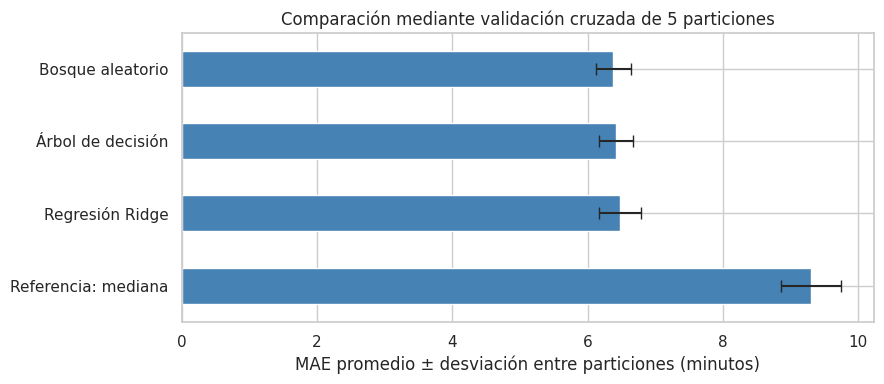

**Selección previa a la prueba:** Bosque aleatorio, con MAE CV de **6.38 minutos** y RMSE CV de 7.91 minutos. Las diferencias entre modelos son descriptivas; no se afirma superioridad estadística.

In [48]:
ax = comparacion['MAE CV (min)'].plot.barh(
    xerr=comparacion['DE MAE (min)'], figsize=(9, 4), color='steelblue', capsize=4)
ax.invert_yaxis()
ax.set(title='Comparación mediante validación cruzada de 5 particiones',
       xlabel='MAE promedio ± desviación entre particiones (minutos)', ylabel='')
plt.tight_layout()
plt.show()
fila = comparacion.loc[ganador]
display(Markdown(f"**Selección previa a la prueba:** {ganador}, con MAE CV de "
                 f"**{fila['MAE CV (min)']:.2f} minutos** y RMSE CV de "
                 f"{fila['RMSE CV (min)']:.2f} minutos. Las diferencias entre modelos "
                 "son descriptivas; no se afirma superioridad estadística."))

**Diferencia entre candidatos.** El bosque obtuvo el menor MAE medio, pero su ventaja frente al árbol fue de solo **0.036 minutos** (aproximadamente 2.2 segundos), menor que la variabilidad entre particiones. Se mantiene la elección de acuerdo con el criterio fijado, sin afirmar una ventaja sustantiva. Si se priorizara simplicidad, el árbol sería una alternativa razonable para evaluar con datos nuevos.

## 6. Evaluación final del modelo seleccionado
Se ajusta la estrategia elegida con todo el conjunto de entrenamiento y se evalúa en la reserva final, junto con la referencia de mediana. Los resultados de esta reserva se utilizan para describir el rendimiento, sin volver a seleccionar parámetros o cambiar de modelo.

In [49]:
modelo_final = clone(pipelines[ganador]).fit(X_train, y_train)
referencia = clone(pipelines['Referencia: mediana']).fit(X_train, y_train)
pred = modelo_final.predict(X_test)
pred_ref = referencia.predict(X_test)
def metricas(real, estimado):
    return {'MAE (min)': mean_absolute_error(real, estimado),
            'RMSE (min)': np.sqrt(mean_squared_error(real, estimado)),
            'R2': r2_score(real, estimado)}
evaluacion_final = pd.DataFrame([
    {'Modelo': ganador, **metricas(y_test, pred)},
    {'Modelo': 'Referencia: mediana', **metricas(y_test, pred_ref)}
]).set_index('Modelo')
display(evaluacion_final.round(4))
mae_final = mean_absolute_error(y_test, pred)
mae_ref = mean_absolute_error(y_test, pred_ref)
mejora = (1 - mae_final / mae_ref) * 100
print(f'Reducción del MAE respecto a la referencia: {mejora:.2f} %')
print(f'Predicciones no positivas: {(pred <= 0).sum()}')
resultados_test = pd.DataFrame({'id_pedido': df_modelo.loc[y_test.index, 'id_pedido'],
    'distancia_km': X_test['distancia_km'], 'real_min': y_test,
    'predicho_min': pred, 'residuo_min': y_test - pred,
    'error_absoluto_min': np.abs(y_test - pred)})
display(resultados_test.head(10).round(2))

,MAE (min),RMSE (min),R2
Modelo,,,
Bosque aleatorio,6.3236,7.8422,0.7188
Referencia: mediana,8.9197,14.9009,-0.0151


Reducción del MAE respecto a la referencia: 29.11 %
Predicciones no positivas: 0


,id_pedido,distancia_km,real_min,predicho_min,residuo_min,error_absoluto_min
1169,PED_01170,1.3,27.0,23.86,3.14,3.14
2226,PED_02227,3.0,34.0,36.41,-2.41,2.41
910,PED_00911,1.0,15.0,24.89,-9.89,9.89
1860,PED_01861,1.3,33.0,27.09,5.91,5.91
379,PED_00380,2.3,30.0,29.38,0.62,0.62
1440,PED_01441,4.1,45.0,32.54,12.46,12.46
2811,PED_02812,3.0,29.0,32.92,-3.92,3.92
3320,PED_03321,4.0,52.0,32.17,19.83,19.83
2077,PED_02078,1.1,37.0,25.09,11.91,11.91
1378,PED_01379,2.4,24.0,30.23,-6.23,6.23


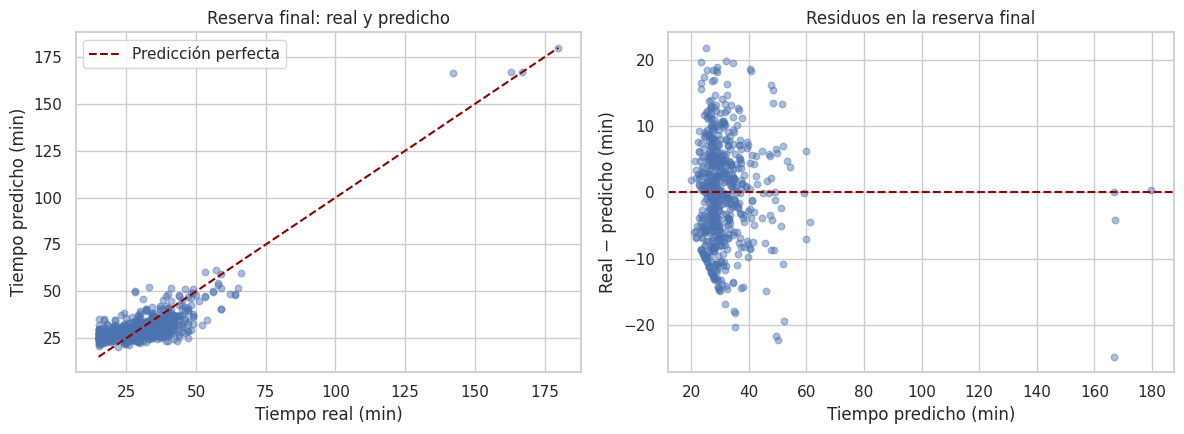

Un residuo positivo indica que el modelo subestimó el tiempo real.
Un residuo negativo indica que lo sobreestimó.


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.45, s=22)
limites = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(limites, limites, '--', color='darkred', label='Predicción perfecta')
axes[0].set(xlabel='Tiempo real (min)', ylabel='Tiempo predicho (min)', title='Reserva final: real y predicho')
axes[0].legend()
axes[1].scatter(pred, y_test - pred, alpha=0.45, s=22)
axes[1].axhline(0, linestyle='--', color='darkred')
axes[1].set(xlabel='Tiempo predicho (min)', ylabel='Real − predicho (min)', title='Residuos en la reserva final')
plt.tight_layout()
plt.show()
print('Un residuo positivo indica que el modelo subestimó el tiempo real.')
print('Un residuo negativo indica que lo sobreestimó.')

**Interpretación de los gráficos.** Las predicciones siguen la tendencia positiva general. La mayor parte de los pedidos se concentra en tiempos cortos o intermedios, donde persisten diferencias de varios minutos y algunos errores superiores a 20 minutos. Los pocos tiempos cercanos a 180 minutos pueden influir especialmente en R² y RMSE. Por ello, un R² global alto no implica igual precisión en todos los rangos ni convierte la correlación del EDA en una garantía predictiva.

### Sensibilidad del error a distancias extremas
Se informan errores en dos segmentos de la misma reserva, sin eliminar pedidos ni reentrenar. El límite superior IQR de distancia se calcula solo con entrenamiento. Esto permite verificar si el promedio general oculta dificultades en trayectos largos. Los grupos pequeños ofrecen estimaciones menos estables; no deben compararse sin considerar sus tamaños. Este corte evalúa distancia, no extremos de la variable objetivo.

In [51]:
q1, q3 = X_train['distancia_km'].quantile([0.25, 0.75])
umbral = q3 + 1.5 * (q3 - q1)
resultados_test['Segmento'] = np.where(resultados_test['distancia_km'] <= umbral,
                                       'Dentro del límite de distancia', 'Sobre el límite de distancia')
segmentos = []
for segmento, grupo in resultados_test.groupby('Segmento'):
    segmentos.append({'Segmento': segmento, 'Pedidos': len(grupo),
        'MAE (min)': grupo['error_absoluto_min'].mean(),
        'RMSE (min)': np.sqrt((grupo['residuo_min'] ** 2).mean())})
sensibilidad = pd.DataFrame(segmentos).set_index('Segmento')
print(f'Límite IQR de distancia aprendido con entrenamiento: {umbral:.2f} km')
display(sensibilidad.round(3))

Límite IQR de distancia aprendido con entrenamiento: 6.40 km


,Pedidos,MAE (min),RMSE (min)
Segmento,,,
Dentro del límite de distancia,565,6.224,7.654
Sobre el límite de distancia,33,8.021,10.558


**Interpretación por segmentos.** En los 565 pedidos de prueba dentro del límite IQR de distancia, el MAE fue de **6,22 minutos**. En los 33 pedidos que superaron ese límite fue de **8,02 minutos**. El promedio global oculta, por tanto, un error mayor en trayectos largos. El segundo segmento contiene pocas observaciones y requiere más datos para evaluar su estabilidad.

## 7. Conclusión del modelado
La siguiente síntesis se calcula con los resultados ejecutados, para que las cifras correspondan a la misma partición, modelos y versiones de librerías.

In [52]:
r = evaluacion_final.iloc[0]
brecha = comparacion.loc[ganador, 'MAE CV (min)'] - comparacion.loc[ganador, 'MAE entrenamiento (min)']
texto = (f"Se compararon tres modelos de regresión y una referencia constante. "
    f"Se seleccionó **{ganador}** por presentar el menor MAE medio en validación cruzada "
    f"({comparacion.loc[ganador, 'MAE CV (min)']:.2f} min). "
    f"En los **{len(y_test)} pedidos** de la reserva final obtuvo un "
    f"**MAE de {r['MAE (min)']:.2f} min**, un RMSE de {r['RMSE (min)']:.2f} min "
    f"y R² de {r['R2']:.3f}. La referencia obtuvo MAE de {mae_ref:.2f} min. "
    f"La variación relativa del MAE respecto a la referencia fue una reducción de {mejora:.2f} %. "
    f"La brecha entre MAE de validación y entrenamiento fue {brecha:.2f} min; "
    "se debe considerar junto con la variabilidad entre particiones al evaluar sobreajuste. "
    "El MAE es un promedio y no garantiza que cada estimación se encuentre dentro de ese margen. "
    "La tabla por segmentos complementa la lectura del error global en presencia de distancias extremas.")
display(Markdown(texto))

Se compararon tres modelos de regresión y una referencia constante. Se seleccionó **Bosque aleatorio** por presentar el menor MAE medio en validación cruzada (6.38 min). En los **598 pedidos** de la reserva final obtuvo un **MAE de 6.32 min**, un RMSE de 7.84 min y R² de 0.719. La referencia obtuvo MAE de 8.92 min. La variación relativa del MAE respecto a la referencia fue una reducción de 29.11 %. La brecha entre MAE de validación y entrenamiento fue 2.07 min; se debe considerar junto con la variabilidad entre particiones al evaluar sobreajuste. El MAE es un promedio y no garantiza que cada estimación se encuentre dentro de ese margen. La tabla por segmentos complementa la lectura del error global en presencia de distancias extremas.

### Evaluación del posible sobreajuste

El bosque aleatorio presenta un MAE promedio de entrenamiento de 4,30 minutos, inferior al obtenido mediante validación cruzada (6,38 minutos). Esta diferencia podría indicar cierto grado de sobreajuste, dado que el modelo obtiene mejores resultados sobre los datos utilizados para su entrenamiento.

Sin embargo, el MAE registrado en el conjunto de prueba (6,32 minutos) es similar al de validación cruzada, lo que sugiere un desempeño relativamente estable sobre observaciones no utilizadas durante el ajuste. Aunque esto no descarta completamente el sobreajuste, respalda la decisión de conservar el modelo seleccionado, reconociendo sus limitaciones.

### Limitaciones y próximos pasos
El origen sintético restringe las conclusiones a este archivo: un buen resultado puede reflejar reglas de generación, sin demostrar utilidad en datos reales. No se dispone de un generador consolidado que reproduzca exactamente el CSV.

El entrenamiento se limita a pedidos entregados con tiempo observado; no estima la probabilidad de cancelación y no debe aplicarse sin más a todos los pedidos. El EDA se realizó previamente sobre el conjunto completo. La reserva actual aporta una evaluación interna del ajuste, pero no reemplaza una evaluación externa con datos nuevos.

La ausencia de fechas y de identificadores de clientes limita las pruebas temporales y por grupos. No se estableció un error máximo aceptable para un uso operativo. Tampoco se demuestra causalidad ni superioridad estadística entre candidatos.

Como continuidad se propone reunir datos reales nuevos, verificar qué variables están disponibles al confirmar el pedido, evaluar estabilidad por ciudad y aplicación, estudiar errores en entregas largas y fijar una tolerancia operativa. Cualquier ajuste posterior debe validarse sin reutilizar esta reserva para elegir parámetros.

## Reproducibilidad y archivos de resultados
Se guardan métricas, predicciones de la reserva y versiones del entorno. La huella del CSV permite verificar que se utilizó el mismo archivo. La semilla hace repetible la partición; diferencias de versión o plataforma pueden ocasionar variaciones numéricas menores.

In [53]:
carpeta_resultados = Path('resultados_tp3')
carpeta_resultados.mkdir(exist_ok=True)
comparacion.to_csv(carpeta_resultados / 'comparacion_validacion_cruzada.csv', encoding='utf-8-sig')
evaluacion_final.to_csv(carpeta_resultados / 'evaluacion_final.csv', encoding='utf-8-sig')
sensibilidad.to_csv(carpeta_resultados / 'sensibilidad_distancia.csv', encoding='utf-8-sig')
resultados_test.to_csv(carpeta_resultados / 'predicciones_reserva.csv', index=False, encoding='utf-8-sig')
entorno = {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
           'scipy': scipy.__version__, 'sklearn': sklearn.__version__, 'seaborn': sns.__version__,
           'semilla': SEED, 'modelo_seleccionado': ganador,
           'sha256_csv': hashlib.sha256(Path('Dataset_Market_Delivery_Argentina.csv').read_bytes()).hexdigest()}
(carpeta_resultados / 'entorno.json').write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series(entorno, name='Valor').to_frame())

,Valor
python,3.13.18
pandas,2.2.3
numpy,2.4.6
scipy,1.15.3
sklearn,1.6.1
seaborn,0.13.1
semilla,42
modelo_seleccionado,Bosque aleatorio
sha256_csv,e405b88ee7d06c6898520e783375663ca091aed8e23338...


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=211131b5-b140-4734-9e7a-3b26466af434' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>